# **LeafySense Classification**

## **Import and Setup**

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

from pathlib import Path
import hashlib, json, random, time, zipfile, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import tensorflow as tf
from tensorflow import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from IPython.display import display

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
HEAD_EPOCHS = 5
FINE_TUNE_EPOCHS = 10
AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

# Limit GPU memory pre-allocation where supported.
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

OUTPUT_DIR = Path('/kaggle/working/leafysense_output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Python:', platform.python_version())
print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))
if not tf.config.list_physical_devices('GPU'):
    print('GPU Tidak Ada')


Python: 3.13.15
TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## **Load Data**

In [2]:
# Dataset path 
base_dir = '/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color'

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Membuat DataFrame 1 gambar (path + label dari nama folder)
paths = sorted(p for p in Path(base_dir).glob('*/*') if p.suffix.lower() in IMG_EXTS)
df = pd.DataFrame({
    'filepath': [str(p) for p in paths],
    'label'   : [p.parent.name for p in paths],
})

# Mapping label ke index 
class_names  = sorted(df['label'].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
df['label_id'] = df['label'].map(class_to_idx).astype('int32')
num_classes = len(class_names)

# Stratified split 70% Train / 15% Val / 15% Test
train_df, remainder_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df['label_id']
)
val_df, test_df = train_test_split(
    remainder_df, test_size=0.50, random_state=SEED, stratify=remainder_df['label_id']
)

# Reset Index
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))

# Simpan riwayat split ke CSV 
split_log = pd.concat([
    train_df.assign(split='train'),
    val_df.assign(split='validation'),
    test_df.assign(split='test')
], ignore_index=True)
split_log.to_csv(OUTPUT_DIR / 'splits.csv', index=False)

print(f"Classes: {class_names}\n")
print(f"Total: {len(df)} | Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}\n")

# Distribusi gambar per kelas di tiap split
summary = pd.concat(
    {'total': df['label'].value_counts(),
     'train': train_df['label'].value_counts(),
     'val'  : val_df['label'].value_counts(),
     'test' : test_df['label'].value_counts()},
    axis=1).loc[class_names]
display(summary)

Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___

,total,train,val,test
label,,,,
Apple___Apple_scab,630,441,95,94
Apple___Black_rot,621,435,93,93
Apple___Cedar_apple_rust,275,193,41,41
Apple___healthy,1645,1152,247,246
Blueberry___healthy,1502,1051,225,226
Cherry_(including_sour)___Powdery_mildew,1052,736,158,158
Cherry_(including_sour)___healthy,854,598,128,128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,513,359,77,77
Corn_(maize)___Common_rust_,1192,834,179,179


## **Data Exploration**

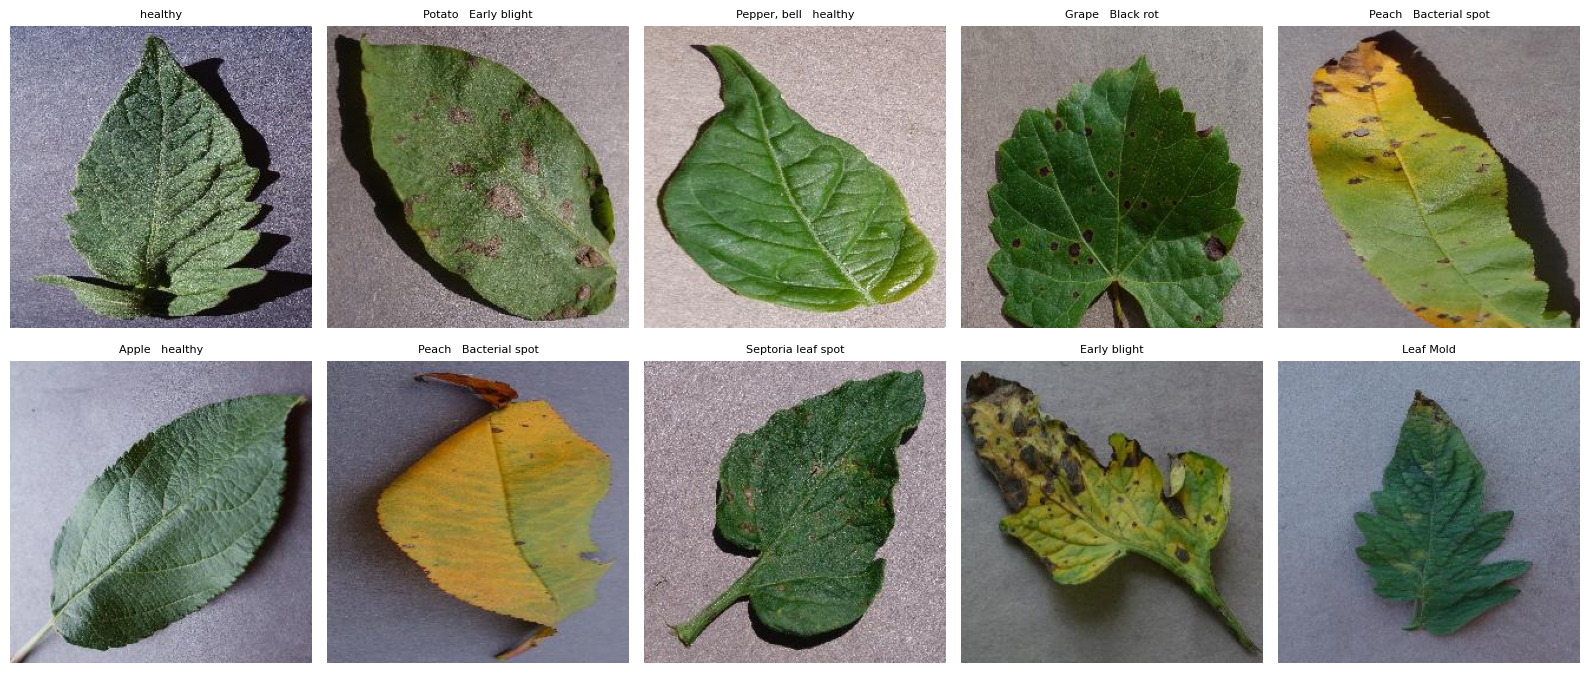

/tmp/ipykernel_23/499368762.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


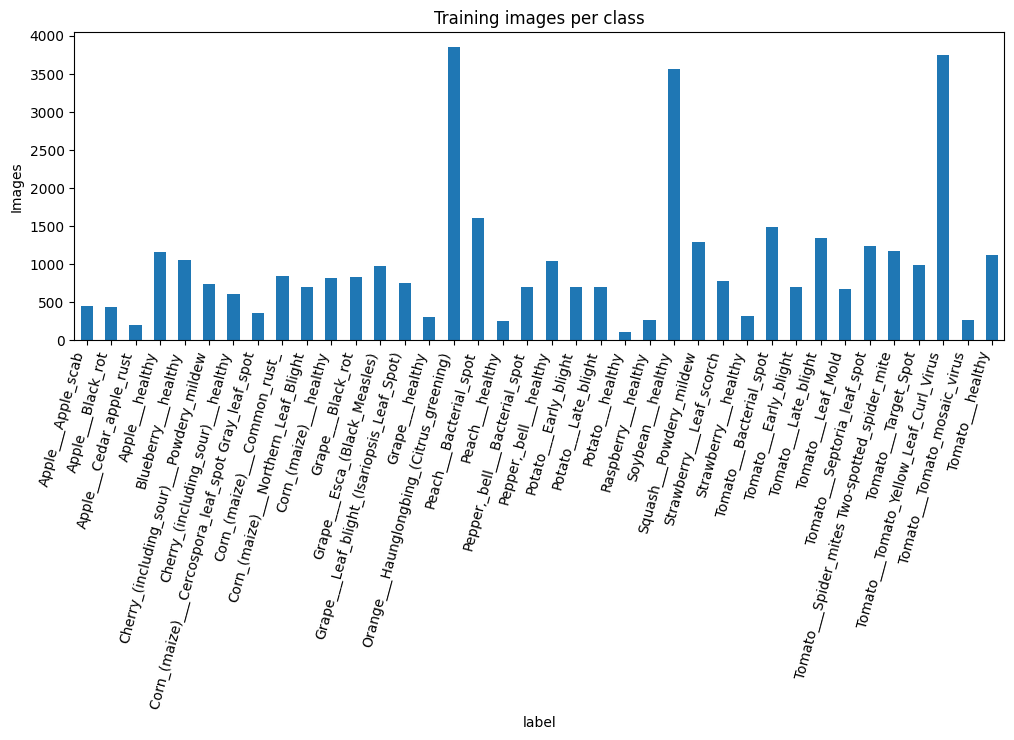

In [3]:
# Visualisasi data train dan distribusi class
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (_, row) in zip(axes.flat, train_df.sample(n=min(10, len(train_df)), random_state=SEED).iterrows()):
    with Image.open(row['filepath']) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(row['label'].replace('Tomato___', '').replace('_', ' '), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

counts = train_df['label'].value_counts().reindex(class_names)
plt.figure(figsize=(12, 4))
counts.plot(kind='bar')
plt.title('Training images per class')
plt.ylabel('Images')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=160, bbox_inches='tight')
plt.show()


## **Make Dataset**

In [4]:
def build_dataset(frame, training=False):
    paths = frame['filepath'].astype(str).to_numpy()
    labels = frame['label_id'].astype('int32').to_numpy() # Label tetap Integer (Sparse)
    
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    
    if training:
        ds = ds.shuffle(
            buffer_size=min(len(frame), 4096), seed=SEED, reshuffle_each_iteration=True
        )

    def load_image(path, label):
        raw = tf.io.read_file(path)
        image = tf.io.decode_image(raw, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])

        image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE], antialias=True)
       
        image = tf.cast(image, tf.float32)  
        return image, label

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    
    options = tf.data.Options()
    options.experimental_deterministic = not training
    ds = ds.with_options(options)
    
    return ds.prefetch(AUTOTUNE)

train_ds = build_dataset(train_df, training=True)
val_ds   = build_dataset(val_df, training=False)
test_ds  = build_dataset(test_df, training=False)

print(train_ds.element_spec)

I0000 00:00:1792441085.534629      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792441085.538416      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


## **Modelling**

In [5]:
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.callbacks import EarlyStopping

# Augmentasi data 
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal', seed=SEED),
    layers.RandomRotation(0.04, seed=SEED),
    layers.RandomZoom(0.10, seed=SEED),
], name='data_augmentation')

# Load Pre-trained Model (MobileNetV3 Small)
base_model = MobileNetV3Small(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False, 
    weights='imagenet',
    include_preprocessing=True 
)

# Freeze bobot base_model agar tidak ikut ditraining ulang
base_model.trainable = False

# Build MobileNetV3Small transfer learning
inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name='rgb_image_0_255')
x = data_augmentation(inputs)
x = base_model(x, training=False)   
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation='softmax', name='class_probabilities')(x)  # Layer klasifikasi akhir

model = keras.Model(inputs, outputs, name='leafysense_mobilenetv3_small')

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy', 
    metrics=['accuracy']
)

model.summary()
print('Trainable parameters:', f'{sum(int(np.prod(v.shape)) for v in model.trainable_variables):,}')


4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "leafysense_mobilenetv3_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_image_0_255 (InputLayer)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 38)             │        21,926 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 961,046 (3.67 MB)

 Trainable params: 21,926 (85.65 KB)

 Non-trainable params: 939,120 (3.58 MB)

Trainable parameters: 21,926


## **Transfer Learning**

In [6]:
# Weight paths
HEAD_WEIGHTS = OUTPUT_DIR / 'best_head.weights.h5'
FINETUNE_WEIGHTS = OUTPUT_DIR / 'best_finetune.weights.h5'

# Callbacks 
head_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(HEAD_WEIGHTS), 
        monitor='val_accuracy', 
        mode='max',
        save_best_only=True, 
        save_weights_only=True, 
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy', 
        mode='max', 
        patience=2, 
        restore_best_weights=False, 
        verbose=1,
    ),
]

# Training 
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=head_callbacks,
    verbose=1,
)

# Load weights terbaik dari validation accuracy
model.load_weights(HEAD_WEIGHTS)
print('Training (head) selesai. Best weights berhasil diload.')

Epoch 1/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6585 - loss: 1.3755
Epoch 1: val_accuracy improved from None to 0.91333, saving model to /kaggle/working/leafysense_output/best_head.weights.h5

Epoch 1: finished saving model to /kaggle/working/leafysense_output/best_head.weights.h5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 3178s 3s/step - accuracy: 0.8085 - loss: 0.7699 - val_accuracy: 0.9133 - val_loss: 0.3103
Epoch 2/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9186 - loss: 0.3067
Epoch 2: val_accuracy improved from 0.91333 to 0.93948, saving model to /kaggle/working/leafysense_output/best_head.weights.h5

Epoch 2: finished saving model to /kaggle/working/leafysense_output/best_head.weights.h5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 70s 59ms/step - accuracy: 0.9233 - loss: 0.2819 - val_accuracy: 0.9395 - val_loss: 0.2023
Epoch 3/5
1187/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9360 - loss: 0.2267
Epoch 3: val_accuracy improved from 0.93948 to 0.94390, saving mo

## **Finetune**

In [7]:
# Unfreeze layer
base_model.trainable = True

# Freeze layer awal kecuali 30 layer akhir
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Freeze batchnormalization
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
)

# Calbacks
fine_tune_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(FINETUNE_WEIGHTS), 
        monitor='val_accuracy', 
        mode='max',
        save_best_only=True, 
        save_weights_only=True, 
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', 
        factor=0.5, 
        patience=1, 
        min_lr=1e-7, 
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy', 
        mode='max', 
        patience=3, 
        restore_best_weights=False, 
        verbose=1,
    ),
]

# Train finetune
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_tune_callbacks,
    verbose=1,
)

# Cek akurasi dari bobot fine-tune
model.load_weights(FINETUNE_WEIGHTS)
fine_loss, fine_acc = model.evaluate(val_ds, verbose=0)

# Cek akurasi dari bobot head (tahap pertama)
model.load_weights(HEAD_WEIGHTS)
head_loss, head_acc = model.evaluate(val_ds, verbose=0)

# Bandingkan dan pilih model yang terbaik
if fine_acc >= head_acc:
    selected_stage = 'fine_tuned'
    selected_weights = FINETUNE_WEIGHTS
    selected_val_acc = fine_acc
else:
    selected_stage = 'frozen_backbone'
    selected_weights = HEAD_WEIGHTS
    selected_val_acc = head_acc

# Muat bobot final terbaik ke dalam model
model.load_weights(selected_weights)
print(f'Selected checkpoint: {selected_stage} | validation accuracy={selected_val_acc:.4f}')

Epoch 1/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9555 - loss: 0.1491
Epoch 1: val_accuracy improved from None to 0.95556, saving model to /kaggle/working/leafysense_output/best_finetune.weights.h5

Epoch 1: finished saving model to /kaggle/working/leafysense_output/best_finetune.weights.h5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 81s 63ms/step - accuracy: 0.9569 - loss: 0.1394 - val_accuracy: 0.9556 - val_loss: 0.1321 - learning_rate: 1.0000e-05
Epoch 2/10
1187/1188 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.9641 - loss: 0.1197
Epoch 2: val_accuracy improved from 0.95556 to 0.96047, saving model to /kaggle/working/leafysense_output/best_finetune.weights.h5

Epoch 2: finished saving model to /kaggle/working/leafysense_output/best_finetune.weights.h5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1802s 2s/step - accuracy: 0.9628 - loss: 0.1193 - val_accuracy: 0.9605 - val_loss: 0.1172 - learning_rate: 1.0000e-05
Epoch 3/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9643 - los

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 34 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Selected checkpoint: fine_tuned | validation accuracy=0.9718


## **Evaluation**

,phase,epoch_in_phase,accuracy,loss,val_accuracy,val_loss,learning_rate
0,frozen_backbone,1,0.808460,0.769906,0.913332,0.310344,NaN
1,frozen_backbone,2,0.923263,0.281899,0.939479,0.202307,NaN
2,frozen_backbone,3,0.938758,0.215513,0.943899,0.170653,NaN
3,frozen_backbone,4,0.945992,0.183055,0.952369,0.155069,NaN
4,frozen_backbone,5,0.949807,0.167011,0.948932,0.150698,NaN
5,fine_tuning,1,0.956883,0.139353,0.955561,0.132121,0.00001
6,fine_tuning,2,0.962802,0.119330,0.960471,0.117195,0.00001
7,fine_tuning,3,0.964538,0.110610,0.962804,0.111757,0.00001
8,fine_tuning,4,0.967432,0.102298,0.964031,0.106926,0.00001
9,fine_tuning,5,0.969852,0.095267,0.963295,0.104619,0.00001


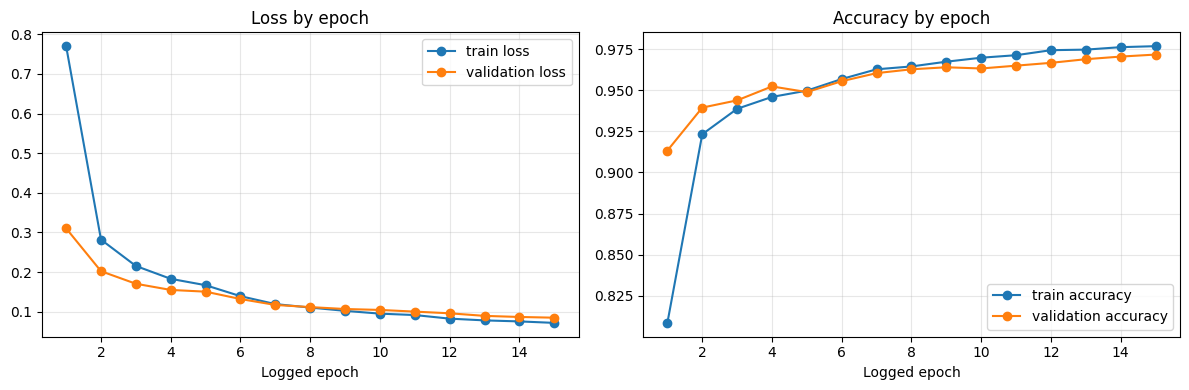

In [8]:
# Simpan training curves dan training history
history_rows = []
for phase_name, hist in [('frozen_backbone', history_head), ('fine_tuning', history_fine)]:
    n_rows = len(hist.history.get('loss', []))
    for i in range(n_rows):
        row = {'phase': phase_name, 'epoch_in_phase': i + 1}
        for key, values in hist.history.items():
            row[key] = float(values[i]) if i < len(values) and values[i] is not None else None
        history_rows.append(row)
history_df = pd.DataFrame(history_rows)
history_df.to_csv(OUTPUT_DIR / 'training_history.csv', index=False)
display(history_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot Loss
axes[0].plot(history_df.index + 1, history_df['loss'], marker='o', label='train loss')
axes[0].plot(history_df.index + 1, history_df['val_loss'], marker='o', label='validation loss')
axes[0].set_title('Loss by epoch')
axes[0].set_xlabel('Logged epoch')
axes[0].legend()
axes[0].grid(True, alpha=.3)

# Plot Accuracy 
axes[1].plot(history_df.index + 1, history_df['accuracy'], marker='o', label='train accuracy')
axes[1].plot(history_df.index + 1, history_df['val_accuracy'], marker='o', label='validation accuracy')
axes[1].set_title('Accuracy by epoch')
axes[1].set_xlabel('Logged epoch')
axes[1].legend()
axes[1].grid(True, alpha=.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()

255/255 ━━━━━━━━━━━━━━━━━━━━ 764s 3s/step
Selected stage: fine_tuned
Validation accuracy: 0.9718
Test accuracy: 0.9735
Test macro F1: 0.9668

Classification report:
                                                    precision    recall  f1-score   support

                                Apple   Apple scab       0.97      0.96      0.96        94
                                 Apple   Black rot       0.98      0.98      0.98        93
                          Apple   Cedar apple rust       1.00      0.98      0.99        41
                                   Apple   healthy       0.99      0.98      0.99       246
                               Blueberry   healthy       1.00      1.00      1.00       226
          Cherry (including sour)   Powdery mildew       1.00      0.99      1.00       158
                 Cherry (including sour)   healthy       1.00      0.99      1.00       128
Corn (maize)   Cercospora leaf spot Gray leaf spot       0.90      0.86      0.88        77
      

,precision,recall,f1-score,support
Apple Apple scab,0.967742,0.957447,0.962567,94.000000
Apple Black rot,0.978495,0.978495,0.978495,93.000000
Apple Cedar apple rust,1.000000,0.975610,0.987654,41.000000
Apple healthy,0.987755,0.983740,0.985743,246.000000
Blueberry healthy,1.000000,1.000000,1.000000,226.000000
Cherry (including sour) Powdery mildew,1.000000,0.993671,0.996825,158.000000
Cherry (including sour) healthy,1.000000,0.992188,0.996078,128.000000
Corn (maize) Cercospora leaf spot Gray leaf spot,0.904110,0.857143,0.880000,77.000000
Corn (maize) Common rust,1.000000,1.000000,1.000000,179.000000
Corn (maize) Northern Leaf Blight,0.921053,0.952381,0.936455,147.000000


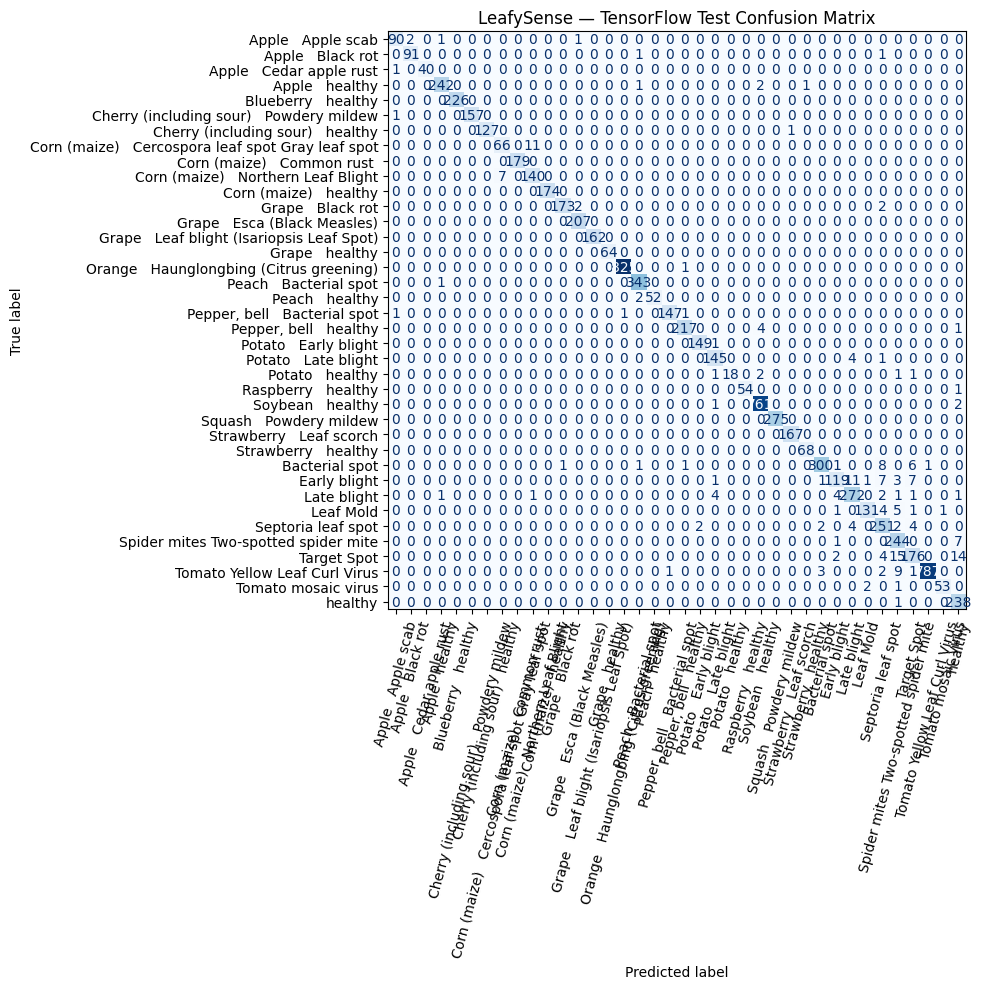

In [9]:
# Test evaluation
test_probabilities = model.predict(test_ds, verbose=1)
class_map = {name: i for i, name in enumerate(class_names)}
y_test = test_df['label'].map(class_map).to_numpy(dtype=np.int32)
y_pred = np.argmax(test_probabilities, axis=1)
test_accuracy = accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
short_names = [name.replace('Tomato___', '').replace('_', ' ') for name in class_names]

print('Selected stage:', selected_stage)
print('Validation accuracy:', round(float(selected_val_acc), 4)) 
print('Test accuracy:', round(float(test_accuracy), 4))
print('Test macro F1:', round(float(test_macro_f1), 4))
print('\nClassification report:')
report_text = classification_report(
    y_test, y_pred, labels=list(range(len(class_names))),
    target_names=short_names, zero_division=0,
)
print(report_text)
report_dict = classification_report(
    y_test, y_pred, labels=list(range(len(class_names))),
    target_names=short_names, output_dict=True, zero_division=0,
)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(OUTPUT_DIR / 'classification_report.csv')
display(report_df)

cm = confusion_matrix(y_test, y_pred, labels=list(range(len(class_names))))
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=short_names).plot(
    ax=ax, xticks_rotation=75, cmap='Blues', colorbar=False, values_format='d'
)
ax.set_title('LeafySense — TensorFlow Test Confusion Matrix')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()


## **Inference**

Mengonversi model ke format TFLite
INFO:tensorflow:Assets written to: /tmp/tmpbc515krp/assets


INFO:tensorflow:Assets written to: /tmp/tmpbc515krp/assets


Saved artifact at '/tmp/tmpbc515krp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='rgb_image_0_255')
Output Type:
  TensorSpec(shape=(None, 38), dtype=tf.float32, name=None)
Captures:
  132640880495504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132640877660112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132640877659536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132640877660304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132640877658192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132640877659728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132640877661072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132640877660880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132640877661264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132640877659344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1326408776

W0000 00:00:1792447852.050762      23 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792447852.050808      23 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792447852.156026      23 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Model dan label berhasil disimpan di: /kaggle/working/leafysense_output

Loading TFLite model dari: /kaggle/working/leafysense_output/model.tflite

Mencoba prediksi gambar asli dari kelas: Tomato___Septoria_leaf_spot


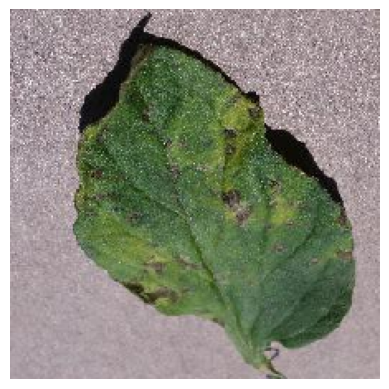

Top 3 Hasil Prediksi:
1. Tomato___Septoria_leaf_spot: 99.63%
2. Tomato___Early_blight: 0.26%
3. Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 0.06%


In [10]:
import random
from tensorflow.keras.preprocessing import image

# Memuat dan inisialisasi TFLite
tflite_dir = OUTPUT_DIR 
tflite_model_path = tflite_dir / 'model.tflite'
label_path = tflite_dir / 'label.txt'

# Konversi model keras ke tflite
print("Mengonversi model ke format TFLite")
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Simpan file .tflite
with open(tflite_model_path, 'wb') as f:
    f.write(tflite_model)

# Simpan file label.txt
with open(label_path, 'w') as f:
    f.write('\n'.join(class_names))
print(f"Model dan label berhasil disimpan di: {tflite_dir}")

# Load tflite model
print(f"\nLoading TFLite model dari: {tflite_model_path}")
interpreter = tf.lite.Interpreter(model_path=str(tflite_model_path))
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

with open(label_path, 'r') as f:
    labels = [line.strip() for line in f.readlines()]

def predict_with_tflite(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    plt.imshow(img)
    plt.axis('off')
    plt.show()
    
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    
    input_data = np.float32(x)
    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()
    
    output_data = interpreter.get_tensor(output_details[0]['index'])
    classes = output_data[0]

    top_3_indices = np.argsort(classes)[-3:][::-1]

    print("Top 3 Hasil Prediksi:")
    for rank, i in enumerate(top_3_indices, start=1):
        predicted_class = labels[i]
        confidence = classes[i] * 100
        print(f"{rank}. {predicted_class}: {confidence:.2f}%")

# Tes Inferensi menggunakan gambar acak dari test_df
random_row = test_df.sample(1).iloc[0]

if 'filepath' in test_df.columns:
    test_image_path = random_row['filepath']
elif 'path' in test_df.columns:
    test_image_path = random_row['path']
else:
    test_image_path = random_row.iloc[0] 

true_label = random_row['label']

print(f"\nMencoba prediksi gambar asli dari kelas: {true_label}")
predict_with_tflite(test_image_path)

## **Save Model**

In [11]:
# Uji kecepatan latensi
sample_images, _ = next(iter(test_ds.take(1)))
single_image = sample_images[:1]

# Warm up 5x
for _ in range(5):
    _ = model(single_image, training=False).numpy()
latency_trials = 30
start = time.perf_counter()
for _ in range(latency_trials):
    _ = model(single_image, training=False).numpy()
latency_ms = (time.perf_counter() - start) * 1000 / latency_trials

model_path = OUTPUT_DIR / 'leafysense_mobilenetv3_small.keras'
model.save(model_path)
with open(OUTPUT_DIR / 'class_names.json', 'w') as f:
    json.dump({'class_names': class_names, 'class_to_idx': class_to_idx}, f, indent=2)

metrics = {
    'framework': 'TensorFlow/Keras',
    'model': 'MobileNetV3Small',
    'selected_stage': selected_stage,
    'num_classes': len(class_names),
    'train_images': int(len(train_df)),
    'validation_images': int(len(val_df)),
    'test_images': int(len(test_df)),
    'test_accuracy': float(test_accuracy),
    'test_macro_f1': float(test_macro_f1),
    'single_image_latency_ms': float(latency_ms),
    'latency_device': 'GPU' if tf.config.list_physical_devices('GPU') else 'CPU',
    'image_size': IMAGE_SIZE,
    'batch_size': BATCH_SIZE,
    'seed': SEED,
    'tensorflow_version': tf.__version__,
    'note': 'PlantVillage is relatively controlled; these results do not guarantee field performance.'
}
with open(OUTPUT_DIR / 'metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
print(json.dumps(metrics, indent=2))


{
  "framework": "TensorFlow/Keras",
  "model": "MobileNetV3Small",
  "selected_stage": "fine_tuned",
  "num_classes": 38,
  "train_images": 38013,
  "validation_images": 8146,
  "test_images": 8146,
  "test_accuracy": 0.9734839184876013,
  "test_macro_f1": 0.9667736803826741,
  "single_image_latency_ms": 150.04215799999656,
  "latency_device": "GPU",
  "image_size": 224,
  "batch_size": 32,
  "seed": 42,
  "tensorflow_version": "2.20.0",
  "note": "PlantVillage is relatively controlled; these results do not guarantee field performance."
}


In [12]:
# Bundle  model dan metrik lainnya untuk download kaggle output
bundle_path = Path('/kaggle/working/leafysense_tensorflow_bundle.zip')
files_to_bundle = [
    model_path,
    OUTPUT_DIR / 'class_names.json',
    OUTPUT_DIR / 'metrics.json',
    OUTPUT_DIR / 'classification_report.csv',
    OUTPUT_DIR / 'training_history.csv',
    OUTPUT_DIR / 'confusion_matrix.png',
    OUTPUT_DIR / 'training_curves.png',
    OUTPUT_DIR / 'class_distribution.png',
    OUTPUT_DIR / 'splits.csv',
]
with zipfile.ZipFile(bundle_path, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for path in files_to_bundle:
        if path.exists():
            zf.write(path, arcname=path.name)
print('Model:', model_path)
print('Downloadable bundle:', bundle_path)
print('Output files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f'{path.name:40s} {path.stat().st_size / (1024**2):.2f} MB')


Model: /kaggle/working/leafysense_output/leafysense_mobilenetv3_small.keras
Downloadable bundle: /kaggle/working/leafysense_tensorflow_bundle.zip
Output files:
best_finetune.weights.h5                 8.70 MB
best_head.weights.h5                     4.24 MB
class_distribution.png                   0.35 MB
class_names.json                         0.00 MB
classification_report.csv                0.00 MB
confusion_matrix.png                     0.64 MB
label.txt                                0.00 MB
leafysense_mobilenetv3_small.keras       8.85 MB
metrics.json                             0.00 MB
model.tflite                             3.65 MB
splits.csv                               9.71 MB
training_curves.png                      0.09 MB
training_history.csv                     0.00 MB
